# Time-shifted Brownian motion

$$ dX_t = 0.5\,dt + dB_t^P $$

Estimate $\sigma$ from quadratic variation, recover $B^Q$, estimate $\psi_{21}$,
recover $\mu$ and $B^P$, then fit SSISDE. `S` denotes the sampled path $X$.
Run all cells with the project Python environment. Figures are saved in this folder.


In [1]:
from pathlib import Path
import os
import sys

roots = [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]
PROJECT_ROOT = next((p for p in roots if (p / 'models/stochastic_sindy.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open the SSISDE checkout first. On Colab, download it with the Black-Scholes setup cell.')
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT / 'experiments/constant')
RESULTS = PROJECT_ROOT / 'outputs/constant'
RESULTS.mkdir(parents=True, exist_ok=True)


In [2]:
%pip install -q -r ../../requirements.txt



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
import pysindy as ps
from sklearn import linear_model
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit
from tqdm import tqdm
import iisignature

from models.diffusion_tuning import diffusion_model, fit_diffusion


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


## Simulate $X$

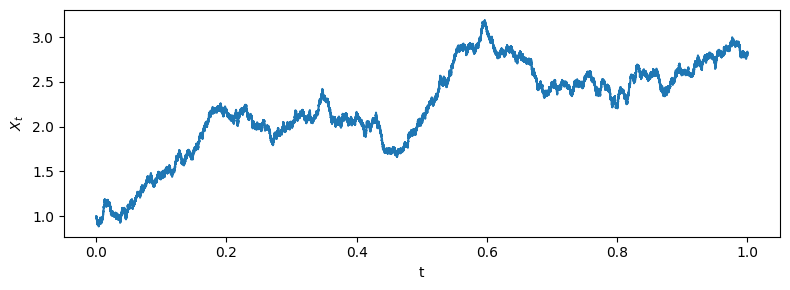

In [4]:
%run -i ../../data_generation/constant.py

plt.figure(figsize=(8, 3))
plt.plot(t, S_)
plt.xlabel('t')
plt.ylabel(r'$X_t$')
plt.tight_layout()
plt.savefig('path.png', dpi=200)
plt.show()


## Estimate $\sigma$ from quadratic variation

Fit a degree-4 polynomial for $\sigma^2$. Select `threshold` and `nu` using the
last 20% of the path, leaving a three-sample gap after the training data.
The known $\sigma$ is used only to report error. The selected fit is then
refitted on the full path. Fits that do not converge, or give zero or negative variance, are rejected.
The search uses `max_iter=10000` and `tol=1e-8`; the original fit retains its
supplied settings for comparison.


In [5]:
%run -i ../../models/quadratic_variation.py


  0%|          | 0/100000 [00:00<?, ?it/s]

 13%|█▎        | 12690/100000 [00:00<00:00, 126883.48it/s]

 25%|██▌       | 25379/100000 [00:00<00:00, 90583.83it/s] 

 35%|███▌      | 35043/100000 [00:00<00:00, 69436.17it/s]

 43%|████▎     | 42618/100000 [00:00<00:00, 58342.25it/s]

...

 93%|█████████▎| 93286/100000 [00:02<00:00, 22293.87it/s]

 96%|█████████▌| 95508/100000 [00:02<00:00, 21818.83it/s]

 98%|█████████▊| 97683/100000 [00:02<00:00, 21146.56it/s]

100%|█████████▉| 99793/100000 [00:02<00:00, 20424.25it/s]

100%|██████████| 100000/100000 [00:02<00:00, 34012.26it/s]

In [6]:
thresholds = [1.0, 3.1, 5.0]
nus = [0.1, 0.2, 0.5]

baseline = diffusion_model(3.1, 0.2)
baseline.fit(S_.reshape(-1, 1), t, x_dot=dQV.reshape(-1, 1))
baseline_sigma = np.sqrt(baseline.predict(S_.reshape(-1, 1))).ravel()

model, sigma_settings, sigma_search = fit_diffusion(
    S_, t, dQV, thresholds, nus, max_iter=10000, tol=1e-8,
)
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1)))
sigma_equation = model.equations(precision=6)[0]
print(f"threshold = {sigma_settings['threshold']}, nu = {sigma_settings['nu']}")
print('sigma^2(X) =', sigma_equation)
(RESULTS / 'diffusion_tuning.json').write_text(json.dumps(sigma_search, indent=2))


threshold = 5.0, nu = 0.5
sigma^2(X) = 1.000393 1


1496

Original settings: sigma RMSE = 0.000196435
Selected settings: sigma RMSE = 0.000196435


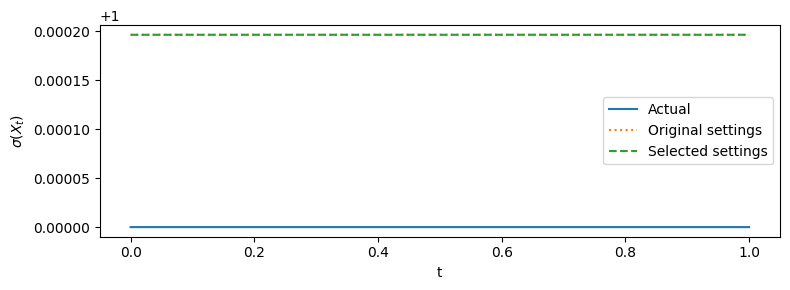

In [7]:
sigma_rmse = float(np.sqrt(np.mean((sigma_pred_.ravel() - sigma_exact_)**2)))
baseline_sigma_rmse = float(np.sqrt(np.mean((baseline_sigma - sigma_exact_)**2)))
print(f'Original settings: sigma RMSE = {baseline_sigma_rmse:.6g}')
print(f'Selected settings: sigma RMSE = {sigma_rmse:.6g}')

plt.figure(figsize=(8, 3))
plt.plot(t, sigma_exact_, label='Actual')
plt.plot(t, baseline_sigma, ':', label='Original settings')
plt.plot(t, sigma_pred_, '--', label='Selected settings')
plt.xlabel('t')
plt.ylabel(r'$\sigma(X_t)$')
plt.legend()
plt.tight_layout()
plt.savefig('diffusion.png', dpi=200)
plt.show()


## Recover $B^Q$ and estimate $\psi_{21}$

In [8]:
%run -i ../../models/q_brownian_motion.py

keep_cols = [0, 1, 3, 4, 5, 13]
%run -i ../../models/signature_regression.py
%run -i ../../data_generation/coarse_graining.py
%run -i ../../models/coarse_diffusion_derivatives.py


/Users/munawarali/Documents/GitHub/SSISDE/models/q_brownian_motion.py:3: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  BQ_[i] = BQ_[i-1] + (S_[i] - S_[i-1])/sigma_pred_[i-1]


  0%|          | 0/1000 [00:00<?, ?it/s]

 20%|██        | 200/1000 [00:00<00:00, 1998.86it/s]

 40%|████      | 402/1000 [00:00<00:00, 2007.69it/s]

 60%|██████    | 603/1000 [00:00<00:00, 2007.44it/s]

 81%|████████  | 806/1000 [00:00<00:00, 2015.37it/s]

100%|██████████| 1000/1000 [00:00<00:00, 2014.83it/s]


/Users/munawarali/Documents/GitHub/SSISDE/data_generation/coarse_graining.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  sigma_pred[i] = sigma_pred_[i*M]


## Recover $\mu$

Method 1 estimates $\psi_{21}$ by signature regression. Method 2 uses the
diffusion estimate. ODE2 uses the additional initial slope $\mu'(X_0)=0$.
All three start from the supplied initial drift $\mu(X_0)$.


In [9]:
%run -i ../../models/drift_coefficients.py
%run -i ../../models/drift_recovery.py

lambda_0 = 0.0
%run -i ../../models/drift_recovery_from_ODE2.py


Method 1: drift RMSE = 0.000348755
Method 2: drift RMSE = 0
ODE2: drift RMSE = 2.96946e-10


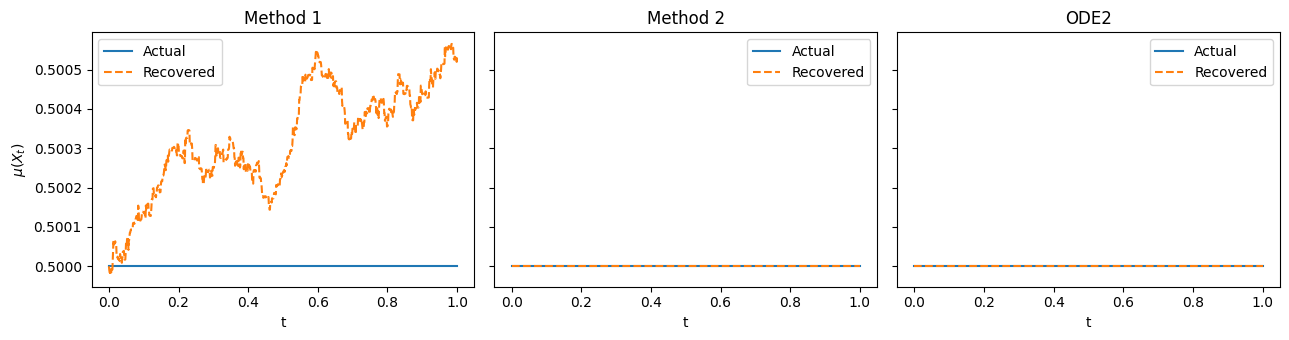

In [10]:
t_ = np.linspace(0, T, K)
drift_estimates = {'Method 1': mu_pred1, 'Method 2': mu_pred2, 'ODE2': mu_pred11}
drift_rmse = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, estimate) in zip(axes, drift_estimates.items()):
    drift_rmse[name] = float(np.sqrt(np.mean((estimate - mu_exact)**2)))
    ax.plot(t_, mu_exact, label='Actual')
    ax.plot(t_, estimate, '--', label='Recovered')
    ax.set_title(name)
    ax.set_xlabel('t')
    ax.legend()
    print(f"{name}: drift RMSE = {drift_rmse[name]:.6g}")
axes[0].set_ylabel(r'$\mu(X_t)$')
fig.tight_layout()
fig.savefig('drift_comparison.png', dpi=200)
plt.show()


## Recover $B^P$ using Method 1

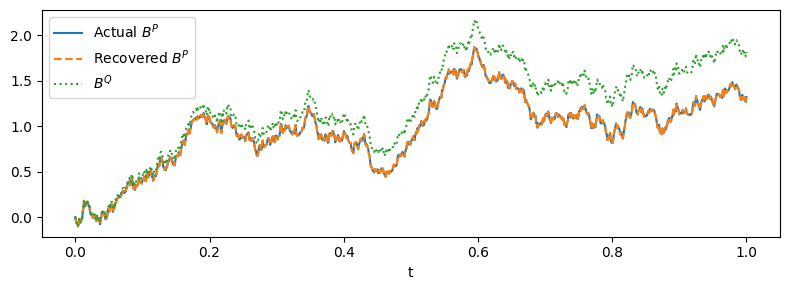

In [11]:
%run -i ../../models/p_brownian_motion.py
model = 'constant'

plt.figure(figsize=(8, 3))
plt.plot(t, W, label=r'Actual $B^P$')
plt.plot(t, BP, '--', label=r'Recovered $B^P$')
plt.plot(t, BQ, ':', label=r'$B^Q$')
plt.xlabel('t')
plt.legend()
plt.tight_layout()
plt.savefig('noise.png', dpi=200)
plt.show()


## SSISDE

MSE: 6.957e-16
μ(X) = 0.499733 + 0.000265338*X
σ(X) = 1.0002
[CV best] alpha=7.63e-05, l1_ratio (rho)=0.70


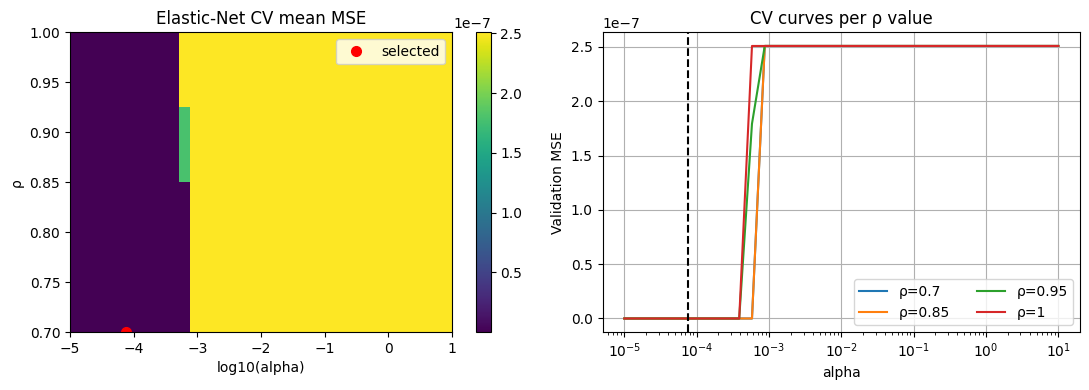

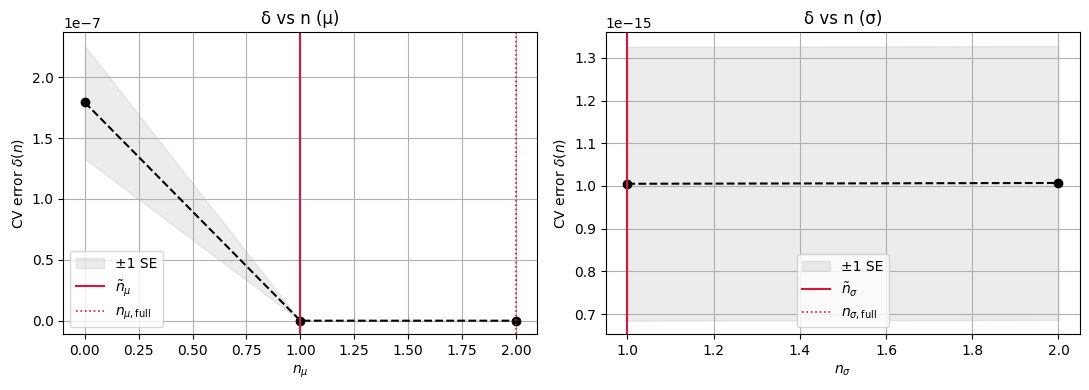

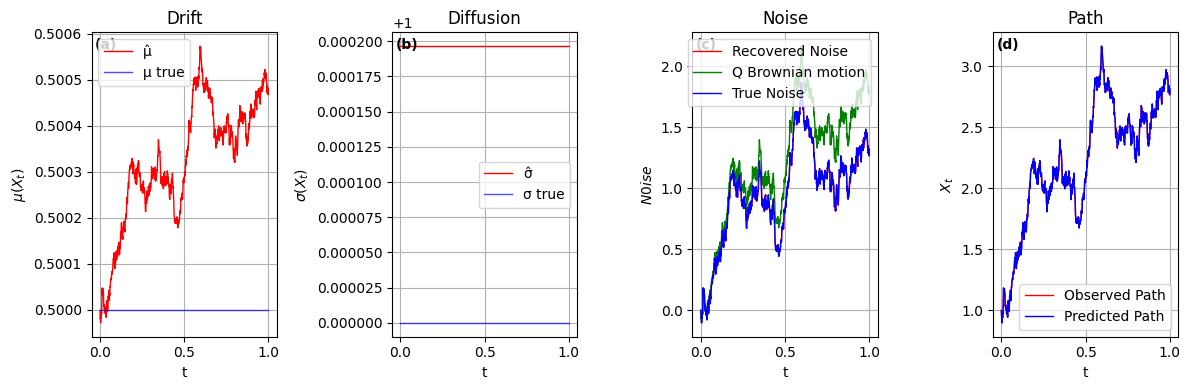

In [12]:
%run -i ../../models/stochastic_sindy.py

identifier = StochSINDy(
    mu_deg=5, si_deg=5, pen='elasticnet', use_cv=True, k=7,
    alphas=np.geomspace(1e-5, 1e1, 35),
    rhos=[0.7, 0.85, 0.95, 1.0], use_1se=True,
)
identifier.fit(S, BP, dt)
identifier.show()
identifier.plot_cv()
identifier.plot_size(count_bias=True)
identifier.plot_results(S, BP, BQ, W, mu_true=mu_exact, si_true=sigma_exact)


In [13]:
results = {
    'experiment': 'constant',
    'seed': seed,
    'samples': N,
    'state_range': [float(S_.min()), float(S_.max())],
    'sigma_settings': sigma_settings,
    'sigma_squared_equation': sigma_equation,
    'baseline_sigma_rmse': baseline_sigma_rmse,
    'sigma_rmse': sigma_rmse,
    'drift_rmse': drift_rmse,
    'noise_rmse': float(np.sqrt(np.mean((BP - W)**2))),
    'ssisde_increment_mse': identifier.mse,
    'ssisde_drift_rmse': float(np.sqrt(np.mean((identifier.mu(S) - mu_exact)**2))),
    'ssisde_diffusion_rmse': float(np.sqrt(np.mean((identifier.si(S) - sigma_exact)**2))),
    'ssisde_mu': identifier._fmt_poly(identifier.mu_c),
    'ssisde_sigma': identifier._fmt_poly(identifier.si_c),
}
(RESULTS / 'results.json').write_text(json.dumps(results, indent=2))
print(f"SSISDE increment MSE: {identifier.mse:.6g}")


SSISDE increment MSE: 6.95717e-16


## Result

The selected diffusion is $\hat\sigma \approx 1.000196$. Method 2 and ODE2 recover the constant drift to numerical accuracy; Method 1 has a small regression error. The selected and original diffusion estimates coincide.
